# Нейросетевой плагин Suricata — v2
### Признаки согласованы с полями eve.json
Все признаки вычисляются **только** из того, что реально пишет Suricata в eve.json:
`flow.duration`, `flow.pkts_toserver`, `flow.pkts_toclient`,
`flow.bytes_toserver`, `flow.bytes_toclient`, `src_port`, `dest_port`, `proto`

In [1]:
import pandas as pd
import numpy as np
import joblib
import warnings
warnings.filterwarnings('ignore')

print('✅ Библиотеки импортированы')

✅ Библиотеки импортированы


## Ячейка 1 — Загрузка датасета

In [2]:
print('📥 Загрузка датасета...')
df = pd.read_parquet('../data/raw/cic-collection.parquet')
print(f'Загружено: {len(df):,} записей')
print(f'Колонки: {list(df.columns[:10])} ...')

📥 Загрузка датасета...
Загружено: 9,167,581 записей
Колонки: ['Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Fwd Packets Length Total', 'Bwd Packets Length Total', 'Fwd Packet Length Max', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Mean'] ...


## Ячейка 2 — Инжиниринг признаков (только из полей eve.json)

Соответствие CIC-IDS → eve.json:

| Признак модели | Источник в CIC-IDS | Источник в eve.json |
|---|---|---|
| `duration` | Flow Duration | `flow.duration` |
| `pkts_toserver` | Total Fwd Packets | `flow.pkts_toserver` |
| `pkts_toclient` | Total Backward Packets | `flow.pkts_toclient` |
| `bytes_toserver` | Fwd Bytes | `flow.bytes_toserver` |
| `bytes_toclient` | Bwd Bytes | `flow.bytes_toclient` |
| `bytes_per_pkt` | Avg Packet Size | вычисляется |
| `bytes_per_sec` | Flow Bytes/s | вычисляется |
| `pkts_per_sec` | Flow Packets/s | вычисляется |
| `fwd_bwd_pkt_ratio` | — | вычисляется |
| `fwd_bwd_bytes_ratio` | — | вычисляется |
| `dest_port` | Destination Port | `dest_port` |
| `proto_tcp` | Protocol | `proto == TCP` |

In [3]:
def build_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Строит признаки ТОЛЬКО из полей, доступных в eve.json.
    Применяется одинаково при обучении и инференсе.
    """
    f = pd.DataFrame()

    # --- Базовые поля (прямое соответствие eve.json) ---
    duration_col  = 'Flow Duration'           if 'Flow Duration'           in df.columns else None
    fwd_pkts_col  = 'Total Fwd Packets'       if 'Total Fwd Packets'       in df.columns else None
    bwd_pkts_col  = 'Total Backward Packets'  if 'Total Backward Packets'  in df.columns else None
    fwd_bytes_col = 'Total Length of Fwd Packets' if 'Total Length of Fwd Packets' in df.columns else 'Fwd Bytes'
    bwd_bytes_col = 'Total Length of Bwd Packets' if 'Total Length of Bwd Packets' in df.columns else 'Bwd Bytes'
    dport_col     = 'Destination Port'        if 'Destination Port'        in df.columns else 'Dst Port'
    proto_col     = 'Protocol'                if 'Protocol'                in df.columns else None

    # Подставляем реально существующие колонки
    for attr, col in [('duration', duration_col), ('fwd_pkts', fwd_pkts_col),
                      ('bwd_pkts', bwd_pkts_col), ('fwd_bytes', fwd_bytes_col),
                      ('bwd_bytes', bwd_bytes_col)]:
        f[attr] = df[col].astype(float) if col and col in df.columns else 0.0

    f['dest_port'] = df[dport_col].astype(float) if dport_col and dport_col in df.columns else 0.0
    f['proto_tcp'] = (df[proto_col] == 6).astype(float) if proto_col and proto_col in df.columns else 0.0

    # --- Производные признаки (вычисляются из базовых) ---
    total_bytes = f['fwd_bytes'] + f['bwd_bytes']
    total_pkts  = f['fwd_pkts']  + f['bwd_pkts']
    dur_safe    = f['duration'].replace(0, np.nan)   # защита от деления на 0
    pkts_safe   = total_pkts.replace(0, np.nan)

    f['bytes_per_sec']       = (total_bytes  / dur_safe).fillna(0)
    f['pkts_per_sec']        = (total_pkts   / dur_safe).fillna(0)
    f['bytes_per_pkt']       = (total_bytes  / pkts_safe).fillna(0)
    f['fwd_bwd_pkt_ratio']   = (f['fwd_pkts'] / (f['bwd_pkts'] + 1))   # +1 защита
    f['fwd_bwd_bytes_ratio'] = (f['fwd_bytes'] / (f['bwd_bytes'] + 1))
    f['fwd_bytes_per_pkt']   = (f['fwd_bytes'] / (f['fwd_pkts'] + 1))
    f['bwd_bytes_per_pkt']   = (f['bwd_bytes'] / (f['bwd_pkts'] + 1))

    # Признак асимметрии: сильный дисбаланс пакетов → признак сканирования/флуда
    f['pkt_asymmetry'] = np.abs(f['fwd_pkts'] - f['bwd_pkts']) / (total_pkts + 1)

    return f


# Список признаков — сохраним, чтобы плагин использовал тот же порядок
FEATURES = [
    'duration', 'fwd_pkts', 'bwd_pkts', 'fwd_bytes', 'bwd_bytes',
    'dest_port', 'proto_tcp',
    'bytes_per_sec', 'pkts_per_sec', 'bytes_per_pkt',
    'fwd_bwd_pkt_ratio', 'fwd_bwd_bytes_ratio',
    'fwd_bytes_per_pkt', 'bwd_bytes_per_pkt',
    'pkt_asymmetry'
]

print('🔧 Построение признаков...')
X_df = build_features(df)

# Метки
y = df['Label'].apply(lambda x: 0 if str(x).lower() in ['benign', 'normal', '0'] else 1).values

# Финальная очистка
X = X_df[FEATURES].replace([np.inf, -np.inf], np.nan).fillna(0).values

print(f'✅ Матрица признаков: {X.shape}')
print(f'   Атаки:  {y.sum():,}  ({y.mean()*100:.1f}%)')
print(f'   Норма:  {(1-y).sum():,}  ({(1-y).mean()*100:.1f}%)')
print(f'\nПризнаки: {FEATURES}')

🔧 Построение признаков...
✅ Матрица признаков: (9167581, 15)
   Атаки:  1,981,392  (21.6%)
   Норма:  7,186,189  (78.4%)

Признаки: ['duration', 'fwd_pkts', 'bwd_pkts', 'fwd_bytes', 'bwd_bytes', 'dest_port', 'proto_tcp', 'bytes_per_sec', 'pkts_per_sec', 'bytes_per_pkt', 'fwd_bwd_pkt_ratio', 'fwd_bwd_bytes_ratio', 'fwd_bytes_per_pkt', 'bwd_bytes_per_pkt', 'pkt_asymmetry']


## Ячейка 3 — Разделение и нормализация

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

# Сохраняем артефакты
import os; os.makedirs('../data/models', exist_ok=True)
joblib.dump(scaler,   '../data/models/scaler_v2.pkl')
joblib.dump(FEATURES, '../data/models/features_v2.pkl')

print(f'Train: {len(X_train):,} | Test: {len(X_test):,}')
print('✅ scaler_v2.pkl и features_v2.pkl сохранены')

Train: 7,334,064 | Test: 1,833,517
✅ scaler_v2.pkl и features_v2.pkl сохранены


## Ячейка 4 — Обучение модели

In [5]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.random.set_seed(42)

model = keras.Sequential([
    layers.Input(shape=(len(FEATURES),)),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid')
], name='suricata_mlp_v2')

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy', keras.metrics.AUC(name='auc'),
             keras.metrics.Precision(name='precision'),
             keras.metrics.Recall(name='recall')]
)

model.summary()

callbacks = [
    keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, monitor='val_auc', mode='max'),
    keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=2, monitor='val_loss')
]

history = model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=20,
    batch_size=4096,
    callbacks=callbacks,
    verbose=1
)

model.save('../data/models/model_v2.h5')
print('\n✅ model_v2.h5 сохранена')

Model: "suricata_mlp_v2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 128)               2048      
                                                                 
 batch_normalization (BatchN  (None, 128)              512       
 ormalization)                                                   
                                                                 
 dropout (Dropout)           (None, 128)               0         
                                                                 
 dense_1 (Dense)             (None, 64)                8256      
                                                                 
 batch_normalization_1 (Batc  (None, 64)               256       
 hNormalization)                                                 
                                                                 
 dropout_1 (Dropout)         (None, 64)            

## Ячейка 5 — Оценка и подбор порога

ROC-AUC: 0.9289
Оптимальный порог: 0.50  (F1=0.8092)

Classification Report:
              precision    recall  f1-score   support

      Normal       0.94      0.96      0.95   1437238
      Attack       0.83      0.79      0.81    396279

    accuracy                           0.92   1833517
   macro avg       0.89      0.87      0.88   1833517
weighted avg       0.92      0.92      0.92   1833517



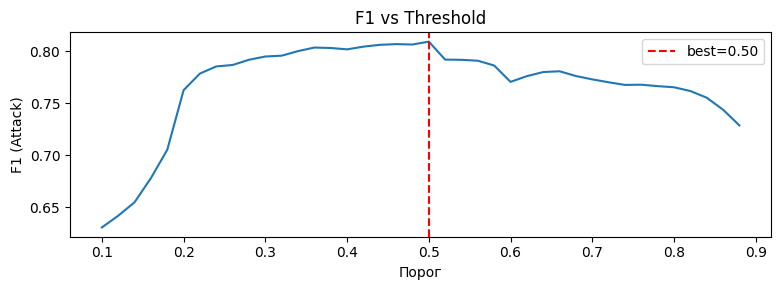

✅ Порог сохранён: threshold_v2.pkl


In [6]:
from sklearn.metrics import classification_report, roc_auc_score, f1_score
import matplotlib.pyplot as plt

y_proba = model.predict(X_test, verbose=0).flatten()

print(f'ROC-AUC: {roc_auc_score(y_test, y_proba):.4f}')

# Подбор оптимального порога по F1 для класса «атака»
thresholds = np.arange(0.1, 0.9, 0.02)
f1_scores = [f1_score(y_test, (y_proba > t).astype(int)) for t in thresholds]
best_threshold = thresholds[np.argmax(f1_scores)]
print(f'Оптимальный порог: {best_threshold:.2f}  (F1={max(f1_scores):.4f})')

# Сохраняем порог — плагин будет его использовать
joblib.dump(best_threshold, '../data/models/threshold_v2.pkl')

y_pred = (y_proba > best_threshold).astype(int)
print('\nClassification Report:')
print(classification_report(y_test, y_pred, target_names=['Normal', 'Attack']))

# График F1 vs порог
plt.figure(figsize=(8, 3))
plt.plot(thresholds, f1_scores)
plt.axvline(best_threshold, color='red', linestyle='--', label=f'best={best_threshold:.2f}')
plt.xlabel('Порог'); plt.ylabel('F1 (Attack)'); plt.title('F1 vs Threshold')
plt.legend(); plt.tight_layout()
plt.savefig('../data/models/threshold_plot.png', dpi=100)
plt.show()
print('✅ Порог сохранён: threshold_v2.pkl')

## Ячейка 6 — Экспорт в ONNX (для плагина)

In [1]:
import tensorflow as tf
import tf2onnx
import numpy as np

model = tf.keras.models.load_model('../data/models/model_v2.h5')
spec = (tf.TensorSpec((None, 15), tf.float32, name="input"),)

model_proto, _ = tf2onnx.convert.from_keras(model, input_signature=spec, opset=13)

with open("../data/models/model_v2.onnx", "wb") as f:
    f.write(model_proto.SerializeToString())

print("✅ ONNX модель сохранена")

✅ ONNX модель сохранена


In [3]:
from pathlib import Path
import tensorflow as tf
import joblib
import numpy as np

model     = tf.keras.models.load_model('../data/models/model_v2.h5')
scaler    = joblib.load('../data/models/scaler_v2.pkl')
threshold = joblib.load('../data/models/threshold_v2.pkl')
features  = joblib.load('../data/models/features_v2.pkl')

# Тест на синтетическом примере
test_vec = np.zeros((1, len(features)))
pred = model.predict(scaler.transform(test_vec), verbose=0)[0][0]

print(f'✅ Модель загружается корректно')
print(f'   Признаков: {len(features)}')
print(f'   Порог:     {threshold:.2f}')
print(f'   Тест-предсказание: {pred:.4f} → {"ATTACK" if pred >= threshold else "Normal"}')
print(f'\nФайлы готовы к использованию плагином:')
for name in ['model_v2.h5','scaler_v2.pkl','features_v2.pkl','threshold_v2.pkl']:
    p = Path(f'../data/models/{name}')
    print(f'   {"✅" if p.exists() else "❌"} {name}')

✅ Модель загружается корректно
   Признаков: 15
   Порог:     0.50
   Тест-предсказание: 0.0334 → Normal

Файлы готовы к использованию плагином:
   ✅ model_v2.h5
   ✅ scaler_v2.pkl
   ✅ features_v2.pkl
   ✅ threshold_v2.pkl


In [3]:
import joblib
import numpy as np

threshold = joblib.load('../data/models/threshold_v2.pkl')
scaler = joblib.load('../data/models/scaler_v2.pkl')
import tensorflow as tf
model = tf.keras.models.load_model('../data/models/model_v2.h5')

# Тест на синтетических примерах — нормальный трафик
normal = np.array([[30.0, 10, 8, 1200, 900, 443, 1,
                    70.0, 0.6, 75.0, 1.25, 1.33, 109.0, 108.0, 0.11]])
normal_scaled = scaler.transform(normal)
pred = model.predict(normal_scaled, verbose=0)[0][0]
print(f'Нормальный трафик: {pred:.4f} → {"ATTACK" if pred >= threshold else "Normal"}')

# Тест — явная атака (много пакетов, короткая сессия)
attack = np.array([[0.1, 5000, 2, 500000, 100, 80, 1,
                    5000000.0, 50020.0, 99.9, 2500.0, 5000.0, 99.9, 48.5, 0.999]])
attack_scaled = scaler.transform(attack)
pred2 = model.predict(attack_scaled, verbose=0)[0][0]
print(f'Атака (flood):     {pred2:.4f} → {"ATTACK" if pred2 >= threshold else "Normal"}')

Нормальный трафик: 0.0000 → Normal
Атака (flood):     1.0000 → ATTACK


In [6]:
import json

eve_path = r'C:\vbox-share\eve.json'

with open(eve_path, encoding='utf-8') as f:
    for line in f:
        try:
            e = json.loads(line)
            if e.get('event_type') == 'flow':
                print(json.dumps(e.get('flow', {}), indent=2))
                break
        except:
            pass

{
  "pkts_toserver": 6,
  "pkts_toclient": 5,
  "bytes_toserver": 444,
  "bytes_toclient": 508,
  "start": "2026-03-23T08:50:09.639559+0000",
  "end": "2026-03-23T08:50:09.671005+0000",
  "age": 0,
  "state": "closed",
  "reason": "timeout",
  "alerted": false
}


In [8]:
import pandas as pd
import numpy as np

df = pd.read_parquet('../data/raw/cic-collection.parquet')

# Берём по 5 реальных примеров каждого класса
normal = df[df['Label'].str.lower() == 'benign'].sample(5, random_state=42)
attacks = df[df['Label'].str.lower() != 'benign'].sample(5, random_state=42)

print("Типы атак в датасете:")
print(df['Label'].value_counts().head(15))

Типы атак в датасете:
Benign            7186189
DDoS-LOIC-HTTP     575364
DoS-Hulk           318740
DDoS-HOIC          198861
Botnet             145968
DDoS               128062
DDoS-NTP           121328
DDoS-TFTP           98833
Bruteforce-SSH      97260
Infiltration        94857
DoS-Goldeneye       52324
DDoS-Syn            47757
DDoS-UDP            28863
DoS-Slowloris       15243
DDoS-MSSQL          11784
Name: Label, dtype: int64
